# Transmissions: The Existing Grid and HVDC Cables

The [basic tutorial](_2_basic_tutorial.ipynb) used one transmission: AC cables between the north and the south, which the model could build from scratch. In reality, a large grid exists already, and new long-distance connections are often built as high-voltage direct current (HVDC) cables, which lose less electricity. This notebook adds both:

| Component | New parameters and functions | What they do |
|---|---|---|
| AC cables | `stockCommissioning` (on a transmission) | the existing grid, given per connection |
| DC cables | `losses` | lower losses than the AC cables |
| | `commissioningFix` | fixes how much capacity is built in each investment period |
| | `fn.plotTransmission` | draws the capacity of a transmission on a map |

## 1. The model of the basic tutorial

The function `buildBasicTutorialModel` in the file [basicTutorialModel.py](basicTutorialModel.py) next to this notebook builds exactly the model of the basic tutorial. `readData` reads one of the CSV files in `examples/data/twoRegions`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import fine as fn
from basicTutorialModel import DATA_PATH, buildBasicTutorialModel, readData

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

esM = buildBasicTutorialModel()
distances = readData("distances.csv")

## 2. The existing AC grid

Inputs of a transmission refer to connections between two regions, so they are given as square `pd.DataFrame`s with the regions as index and columns, like the `distances` in the basic tutorial. The entry in row `north` and column `south` belongs to the connection from the north to the south. Our data contains the capacity of the AC cables that already connect the two regions:

In [2]:
existingCapacityAC = readData("existingCapacityACcables.csv")
existingCapacityAC  # GW

,north,south
north,0.0,29.0
south,29.0,0.0


As for the existing gas power plants in the [Conversions notebook](_5_conversions.ipynb), we add this capacity to the existing component `"AC cables"` with **`stockCommissioning`** and `esM.updateComponent`. We assume that the cables were built in 2010. With their lifetime of 40 years, they are available in all three investment periods. FINE can still build more AC cables on top of them.

In [3]:
esM.updateComponent("AC cables", {"stockCommissioning": {2010: existingCapacityAC}})

## 3. HVDC cables

The data also contains 10 GW of DC cables between the north and the south. Such cables are planned in Germany to bring wind power from the coast to the south. We assume that they start operating in 2030. Compared with the AC cables, they have:

- lower **`losses`**: 0.003 % per km instead of 0.01 % per km, i.e. about 1.1 % instead of 3.6 % over the 357 km between the regions,
- a higher investment per GW and km, since every cable needs a converter station at each end.

Their construction is not a decision of the optimization: they are built in 2030 as planned. **`commissioningFix`** fixes the capacity that is newly built (commissioned) in an investment period. As a dictionary, it has to contain every investment period: nothing is built in 2020 and 2040, and the 10 GW in 2030. Once built, the cables stay available for their lifetime, so they also exist in 2040. (In contrast, `capacityFix` would fix the total capacity in a period, no matter when it was built.)

In [4]:
existingCapacityDC = readData("existingCapacityDCcables.csv")
noCapacity = existingCapacityDC * 0

esM.add(
    fn.Transmission(
        esM=esM,
        name="DC cables",
        commodity="electricity",
        hasCapacityVariable=True,
        distances=distances,
        losses=0.00003,  # per km
        commissioningFix={2020: noCapacity, 2030: existingCapacityDC, 2040: noCapacity},
        investPerCapacity=2.5,  # million Euro per GW and km
        opexPerCapacity=0.025,
        interestRate=0.08,
        economicLifetime=40,
    )
)

## 4. Optimize

In [5]:
esM.aggregateTemporally(numberOfTypicalPeriods=8)

In [6]:
esM.optimize(
    timeSeriesAggregation=True,
    solver=fn.utils.ImplementedSolvers.STANDARD_SOLVER.value,
)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (80 outputs left out)

Solved with barrier


    2362    6.0179835e+05   0.000000e+00   0.000000e+00      1s


Solved in 2362 iterations and 0.51 seconds (0.70 work units)


Optimal objective  6.017983465e+05


## 5. Results

### Capacities

The summary of the transmissions has one row per connection (`LocationIn`) and one column per destination. We take the connection from the north to the south:

In [7]:
transmission = {}
for year in esM.investmentPeriodNames:
    summary = esM.getOptimizationSummary("TransmissionModel", outputLevel=1, ip=year)
    for component in ["AC cables", "DC cables"]:
        for prop in ["capacity", "commissioning"]:
            transmission[component, prop, year] = summary.loc[
                (component, prop, "[GW_el]", "north"), "south"
            ]
transmission = pd.Series(transmission).unstack()
transmission.columns.name = "north to south [GW]"
transmission.round(1)

north to south [GW]      2020  2030  2040
AC cables capacity       29.0  29.0  29.0
          commissioning   0.0   0.0   0.0
DC cables capacity        0.0  10.0  10.0
          commissioning   0.0  10.0   0.0

The existing 29 GW of AC cables are enough: the model does not build any new ones (`commissioning` stays 0), while it built up to 26 GW from scratch in the basic tutorial. The DC cables are built in 2030 exactly as fixed, and they are still available in 2040, although nothing is commissioned then.

### On a map

`fn.plotTransmission` draws the capacity of a transmission as a line between the regions, its width proportional to the capacity. It needs a file with the lines, here `lines.geojson` from the data folder, whose columns `loc0` and `loc1` name the two regions of each line. `fn.plotLocations` draws the regions underneath. `plotTransmission` draws the largest capacity of a map with the width `linewidth`; we set it in proportion to the capacity, so that the two maps can be compared:

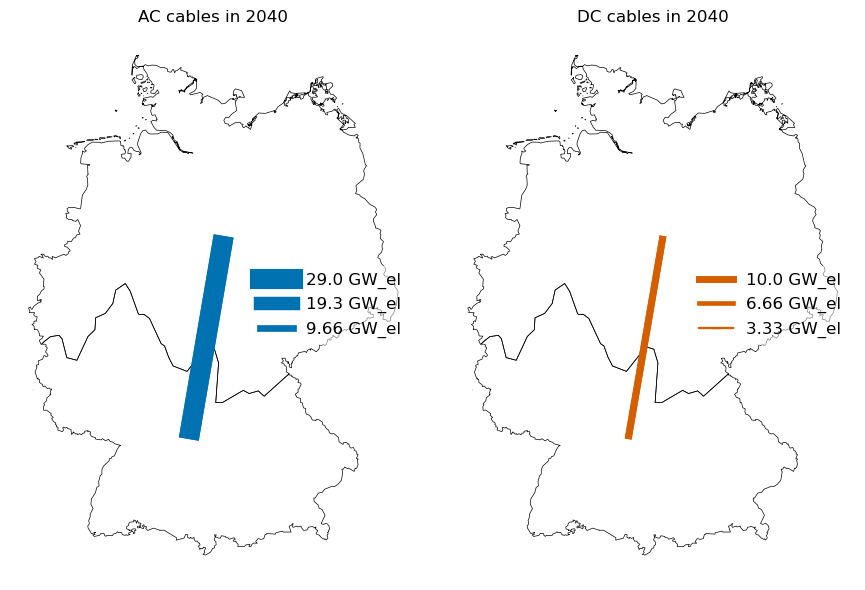

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, (component, color) in zip(
    axes, {"AC cables": "#0072B2", "DC cables": "#D55E00"}.items()
):
    fn.plotLocations(
        DATA_PATH / "regions.geojson", indexColumn="region", fig=fig, ax=ax
    )
    fn.plotTransmission(
        esM,
        component,
        DATA_PATH / "lines.geojson",
        loc0="loc0",
        loc1="loc1",
        ip=2040,
        color=color,
        linewidth=transmission.loc[(component, "capacity"), 2040] / 2,
        fig=fig,
        ax=ax,
    )
    ax.set_title(f"{component} in 2040")

### Flows

The yearly flow from the north to the south (and back) is the `operation` of each connection:

In [9]:
flows = {}
for year in esM.investmentPeriodNames:
    summary = esM.getOptimizationSummary("TransmissionModel", outputLevel=1, ip=year)
    for component in ["AC cables", "DC cables"]:
        operation = summary.loc[(component, "operation")].droplevel("Unit")
        flows[component, "north to south", year] = (
            operation.loc["north", "south"] / 1000
        )
        flows[component, "south to north", year] = (
            operation.loc["south", "north"] / 1000
        )
flows = pd.Series(flows).unstack()
flows.columns.name = "Flow [TWh per year]"
flows.round(1)

Flow [TWh per year]       2020  2030  2040
AC cables north to south  20.8  52.5  35.8
          south to north  12.5   0.1   3.3
DC cables north to south   0.0  46.6  39.7
          south to north   0.0   1.7  13.4

Most of the electricity flows from the windy north to the south. Once the DC cables exist, they carry almost as much as the AC cables, although their capacity is only about a third as large: since less electricity is lost on the way, the model uses them first. In 2030, the DC cables run at full capacity for about 4800 hours (48 TWh with 10 GW), the AC cables for only about 1800 hours (53 TWh with 29 GW).

## Things to try

- Forbid new AC cables by setting `capacityMax` of the AC cables to the existing capacity. How much more does the system cost (`esM.objectiveValue`)?
- Let the model decide about the DC cables: replace `commissioningFix` by a `commissioningMax` of 10 GW in 2020 and no limit in later periods.
- Add a hydrogen pipeline: a `Transmission` with the commodity `hydrogen` (see the [Conversions notebook](_5_conversions.ipynb) for the hydrogen components).